# Preview random frames from both classes

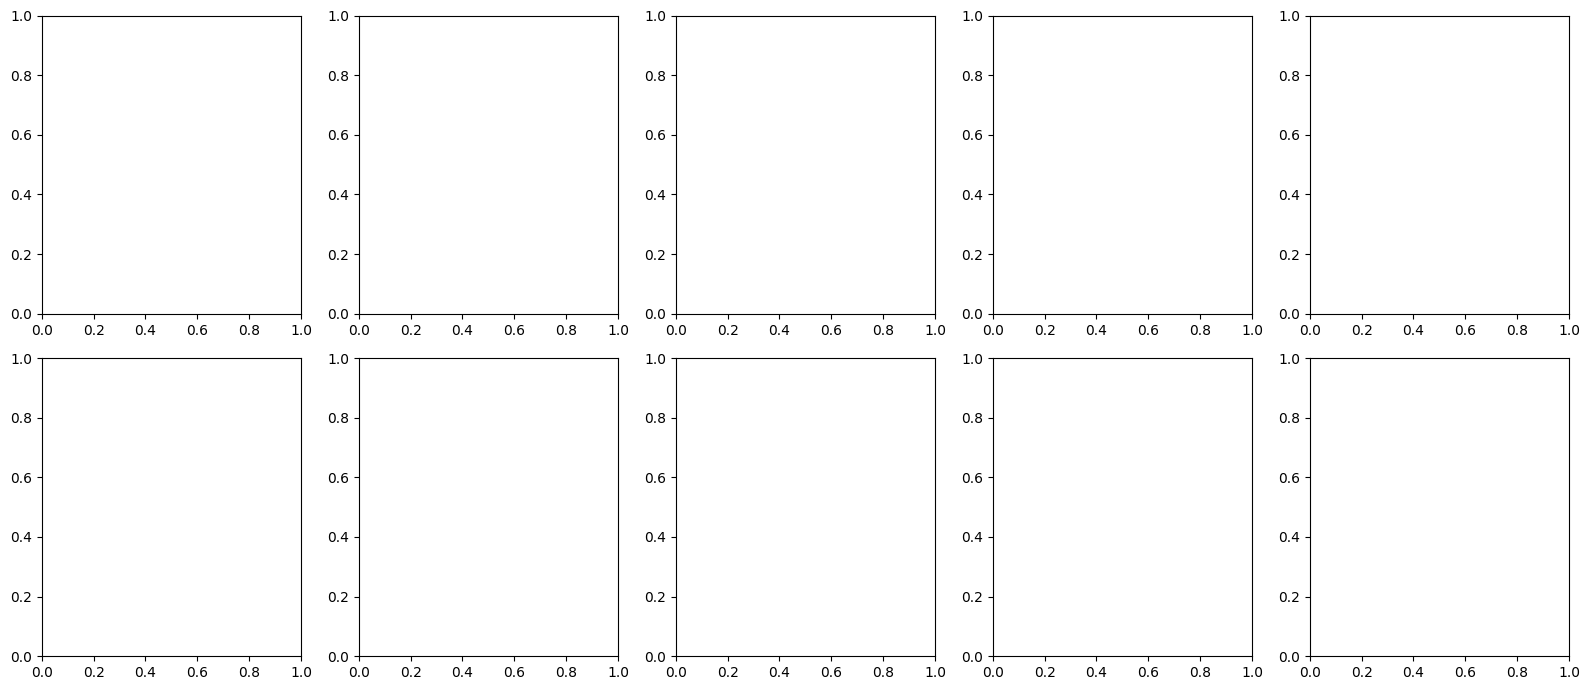

In [ ]:

from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image

PROJECT = Path("/content/drive/MyDrive/Component03")
ACCIDENT_DATASET = PROJECT / "accident_dataset"

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for row, label in enumerate(["normal", "accident"]):
    folder = ACCIDENT_DATASET / "train" / label
    images = list(folder.glob("*.jpg"))

    selected = random.sample(images, min(5, len(images)))

    for col, path in enumerate(selected):
        axes[row, col].imshow(Image.open(path))
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


# Prepare Google Colab for ResNet18 training

Install and import libraries

In [ ]:

%pip install -q torch torchvision scikit-learn matplotlib pandas


# Mount Drive and check the GPU

In [ ]:

from google.colab import drive
import torch

drive.mount("/content/drive")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Mounted at /content/drive
Selected device: cpu


# Copy the dataset to Colab local storage

In [ ]:

import shutil
from pathlib import Path

LOCAL_DATASET = Path("/content/accident_dataset")

if LOCAL_DATASET.exists():
    shutil.rmtree(LOCAL_DATASET)

shutil.copytree(ACCIDENT_DATASET, LOCAL_DATASET)

for split in ["train", "val", "test"]:
    for label in ["normal", "accident"]:
        count = len(list(
            (LOCAL_DATASET / split / label).glob("*.jpg")
        ))
        print(split, label, count)


train normal 222
train accident 164
val normal 70
val accident 34
test normal 37
test accident 43


# 4. Load the dataset for training

# Create data loaders

In [5]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_ds = datasets.ImageFolder(
    LOCAL_DATASET / "train",
    transform=train_transform
)

val_ds = datasets.ImageFolder(
    LOCAL_DATASET / "val",
    transform=eval_transform
)

test_ds = datasets.ImageFolder(
    LOCAL_DATASET / "test",
    transform=eval_transform
)

assert train_ds.class_to_idx == val_ds.class_to_idx
assert train_ds.class_to_idx == test_ds.class_to_idx

class_names = train_ds.classes
accident_idx = train_ds.class_to_idx["accident"]

print("Class mapping:", train_ds.class_to_idx)
print("Training frames:", len(train_ds))
print("Validation frames:", len(val_ds))
print("Testing frames:", len(test_ds))

train_loader = DataLoader(
    train_ds, batch_size=16,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_ds, batch_size=16,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_ds, batch_size=16,
    shuffle=False, num_workers=2
)


Class mapping: {'accident': 0, 'normal': 1}
Training frames: 386
Validation frames: 104
Testing frames: 80


# 5. Create the ResNet18 neural network

We'll load a pretrained ResNet18 and replace its final classification layer with a two-class output layer.

# Initialize the model

In [6]:

import torch.nn as nn
from torchvision.models import (
    resnet18, ResNet18_Weights
)

torch.manual_seed(42)

model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# Freeze the initial feature extractor
for parameter in model.parameters():
    parameter.requires_grad = False

# Fine-tune the final residual block
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

# Replace the classification layer
model.fc = nn.Linear(
    model.fc.in_features, 2
)

model = model.to(device)

print("ResNet18 initialized successfully")
print("Output classes:", class_names)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]


ResNet18 initialized successfully
Output classes: ['accident', 'normal']


# 6. Train ResNet18

We will start with 15 epochs, saving the checkpoint that achieves the best validation macro F1-score.

# Configure training

In [7]:

import numpy as np
from sklearn.metrics import f1_score

labels = np.array(train_ds.targets)
counts = np.bincount(labels, minlength=2)

weights = len(labels) / (2.0 * counts)
class_weights = torch.tensor(
    weights, dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001,
    weight_decay=0.0001
)

EPOCHS = 15

CHECKPOINT_DIR = (
    PROJECT / "accident_model_results"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_PATH = CHECKPOINT_DIR / "resnet18_best.pt"

print("Class weights:", weights)
print("Checkpoint destination:", BEST_PATH)


Class weights: [1.17682927 0.86936937]
Checkpoint destination: /content/drive/MyDrive/Component03/accident_model_results/resnet18_best.pt


# Start training

In [8]:

from tqdm.auto import tqdm
from sklearn.metrics import f1_score
import copy

history = []
best_f1 = -1.0

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)

    train_loss = running_loss / len(train_ds)

    # Validation
    model.eval()
    true_labels = []
    predictions = []
    val_loss_sum = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * len(images)

            preds = outputs.argmax(dim=1)

            true_labels.extend(labels.cpu().tolist())
            predictions.extend(preds.cpu().tolist())

    val_loss = val_loss_sum / len(val_ds)

    val_f1 = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss={train_loss:.4f}, "
        f"Val Loss={val_loss:.4f}, "
        f"Val F1={val_f1:.4f}"
    )

    if val_f1 > best_f1:
        best_f1 = val_f1

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_to_idx": train_ds.class_to_idx,
            "epoch": epoch + 1,
            "validation_macro_f1": val_f1
        }, BEST_PATH)

        print("Saved new best model!")

print("\nTraining completed")
print("Best validation macro F1:", best_f1)


Epoch 1/15:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 1: Train Loss=0.3616, Val Loss=0.7063, Val F1=0.7327
Saved new best model!


Epoch 2/15:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 2: Train Loss=0.1662, Val Loss=0.6328, Val F1=0.6941


Epoch 3/15:   0%|          | 0/25 [00:00<?, ?it/s]

...

Epoch 14/15:   0%|          | 0/25 [00:00<?, ?it/s]


  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e142421c400>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ a

Epoch 14: Train Loss=0.0259, Val Loss=0.7227, Val F1=0.7203


Epoch 15/15:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 15: Train Loss=0.0439, Val Loss=0.8393, Val F1=0.7332

Training completed
Best validation macro F1: 0.7752246615857126


In [9]:
from pathlib import Path

BEST_PATH = Path(
    "/content/drive/MyDrive/Component03/"
    "accident_model_results/resnet18_best.pt"
)

print("Best model saved:", BEST_PATH.exists())

if BEST_PATH.exists():
    print(
        "Model size:",
        round(BEST_PATH.stat().st_size / (1024**2), 2),
        "MB"
    )

Best model saved: True
Model size: 42.71 MB


# Plot training history

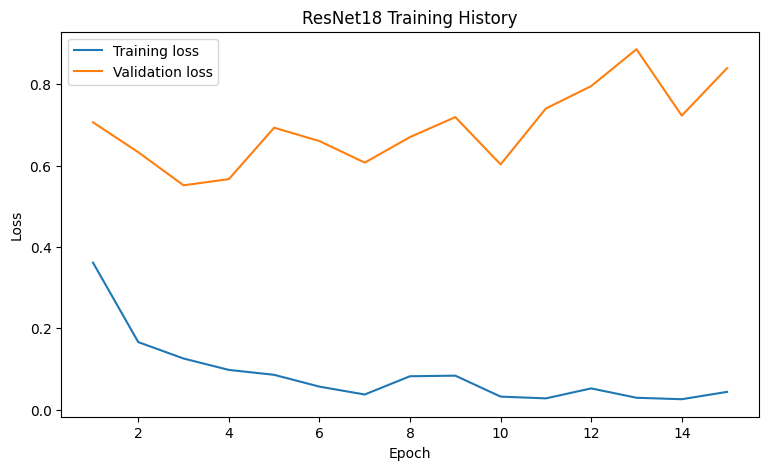

,epoch,train_loss,val_loss,val_macro_f1
0,1,0.361570,0.706298,0.732703
1,2,0.166232,0.632767,0.694118
2,3,0.125891,0.551406,0.702763
3,4,0.097892,0.566629,0.733675
4,5,0.085840,0.693004,0.702763
5,6,0.056769,0.660088,0.720280
6,7,0.037511,0.607225,0.751736
7,8,0.082343,0.669974,0.775225
8,9,0.083757,0.718995,0.728913
9,10,0.032303,0.602788,0.728913


In [10]:

import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training loss"
)

ax.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation loss"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("ResNet18 Training History")
ax.legend()
plt.show()

display(history_df)
history_df.to_csv(
    CHECKPOINT_DIR / "training_history.csv",
    index=False
)


# 7. Evaluate the trained accident classifier

# Calculate validation classification results

VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

    accident       0.80      0.59      0.68        34
      normal       0.82      0.93      0.87        70

    accuracy                           0.82       104
   macro avg       0.81      0.76      0.78       104
weighted avg       0.82      0.82      0.81       104



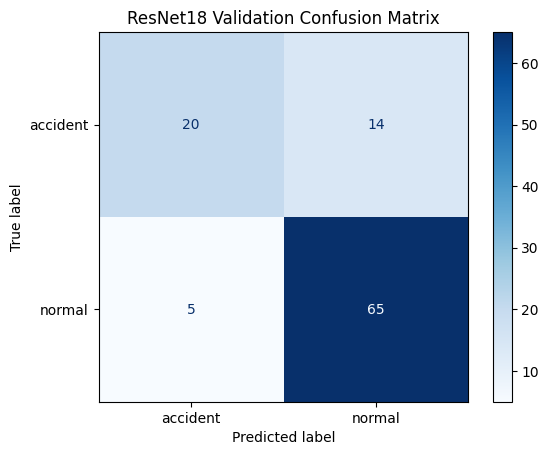

In [11]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

checkpoint = torch.load(
    BEST_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)
model.eval()

all_true = []
all_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(1)

        all_true.extend(labels.tolist())
        all_pred.extend(predictions.cpu().tolist())

print("VALIDATION CLASSIFICATION REPORT")

print(classification_report(
    all_true,
    all_pred,
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    all_true,
    all_pred,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(cmap="Blues")

plt.title("ResNet18 Validation Confusion Matrix")
plt.show()


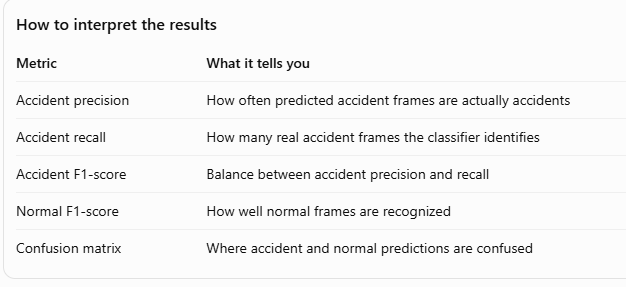